## Retrieve Target Image

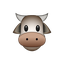

In [ ]:
import requests
import io
from PIL import Image

EMOJI_NAME = "cow"

url = f"https://raw.githubusercontent.com/wryzxec/growing_ca/main/assets/{EMOJI_NAME}.png"

response = requests.get(url)
img = Image.open(io.BytesIO(response.content))

display(img)

## Create Target Tensor

In [ ]:
import torchvision.transforms as transforms

transform = transforms.Compose([
    transforms.ToTensor()
])

target = transform(img)
target = target.unsqueeze(0)

print("target shape:", target.shape)

target shape: torch.Size([1, 4, 64, 64])


# Basic Model

In [ ]:
import torch

class BasicCAModel(torch.nn.Module):
  def __init__(self):
    super().__init__()

    sobel_x = torch.tensor([
        [-1, 0, 1],
        [-2, 0, 2],
        [-1, 0, 1]
    ], dtype=torch.float32)

    sobel_y = sobel_x.T

    kernel_x = sobel_x.view(1, 1, 3, 3).repeat(16, 1, 1, 1)
    kernel_y = sobel_y.view(1, 1, 3, 3).repeat(16, 1, 1, 1)

    self.conv1 = torch.nn.Conv2d(48, 128, 1)
    self.conv2 = torch.nn.Conv2d(128, 16, 1)

    torch.nn.init.zeros_(self.conv2.weight)
    torch.nn.init.zeros_(self.conv2.bias)

    self.register_buffer("kernel_x", kernel_x)
    self.register_buffer("kernel_y", kernel_y)

  def perceive(self, state):
    grad_x = torch.conv2d(
        state,
        self.kernel_x,
        padding=1,
        groups=16
    )

    grad_y = torch.conv2d(
        state,
        self.kernel_y,
        padding=1,
        groups=16
    )

    perception_grid = torch.cat([state, grad_x, grad_y], dim=1)

    return perception_grid

  def alive_masking(self, state_grid):
    alive = torch.nn.functional.max_pool2d(
        state_grid[:, 3:4], kernel_size=3, stride=1, padding=1) > 0.1
    return alive

  def forward(self, state):
    pre_alive = self.alive_masking(state)

    x = self.perceive(state)
    x = self.conv1(x)
    x = torch.relu(x)
    x = self.conv2(x)

    x = state + x
    post_alive = self.alive_masking(x)
    x = x * (pre_alive & post_alive)

    return x

# Training

In [ ]:

device = torch.device("cuda")

model = BasicCAModel().to(device)
target = target.to(device)

optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

NUM_EPOCHS = 1000
BATCH_SIZE = 1
TMIN = 64
TMAX = 96

for epoch in range(NUM_EPOCHS):

    optimizer.zero_grad()

    state = torch.zeros(
        BATCH_SIZE, 16, 64, 64,
        device=device
    )

    state[:, 3:, 32, 32] = 1.0

    for _ in range(torch.randint(TMIN, TMAX+1, ()).item()):
        state = model(state)

    prediction = state[:, :4]

    loss = torch.mean((prediction - target) ** 2)

    loss.backward()
    optimizer.step()

    if epoch % 100 == 0:
      print(f"Epoch {epoch}, Loss: {loss.item()}")

print(f"Final Loss: {loss.item()}")


Epoch 0, Loss: 0.11596676707267761
Epoch 100, Loss: 0.021565739065408707
Epoch 200, Loss: 0.016216468065977097
Epoch 300, Loss: 0.021161697804927826
Epoch 400, Loss: 0.01896219328045845
Epoch 500, Loss: 0.02765997126698494
Epoch 600, Loss: 0.011175489984452724
Epoch 700, Loss: 0.012997167184948921
Epoch 800, Loss: 0.012489315122365952
Epoch 900, Loss: 0.007921900600194931
Final Loss: 0.0073669664561748505


In [ ]:
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

fig, ax = plt.subplots()

state = torch.zeros(1, 16, 64, 64, device="cuda")
state[:, 3:, 32, 32] = 1.0

result = state[0, :4].permute(1, 2, 0).clamp(0, 1)
frame = ax.imshow(result.cpu())

def animate(i):
    global state
    with torch.no_grad():
      state = model(state)
      result = state[0, :4]
      result = result.permute(1, 2, 0).clamp(0,1)

      frame.set_data(result.cpu())

    return [frame]


anim = FuncAnimation(
    fig,
    animate,
    frames=128,
    interval=64,
    blit=True
)

plt.close(fig)

HTML(anim.to_jshtml())

# Stochastic CA Model

In [ ]:
import torch

class StochasticCAModel(torch.nn.Module):
  def __init__(self):
    super().__init__()

    sobel_x = torch.tensor([
        [-1, 0, 1],
        [-2, 0, 2],
        [-1, 0, 1]
    ], dtype=torch.float32)

    sobel_y = sobel_x.T

    kernel_x = sobel_x.view(1, 1, 3, 3).repeat(16, 1, 1, 1)
    kernel_y = sobel_y.view(1, 1, 3, 3).repeat(16, 1, 1, 1)

    self.conv1 = torch.nn.Conv2d(48, 128, 1)
    self.conv2 = torch.nn.Conv2d(128, 16, 1)

    torch.nn.init.zeros_(self.conv2.weight)
    torch.nn.init.zeros_(self.conv2.bias)

    self.register_buffer("kernel_x", kernel_x)
    self.register_buffer("kernel_y", kernel_y)

  def perceive(self, state):
    grad_x = torch.conv2d(
        state,
        self.kernel_x,
        padding=1,
        groups=16
    )

    grad_y = torch.conv2d(
        state,
        self.kernel_y,
        padding=1,
        groups=16
    )

    perception_grid = torch.cat([state, grad_x, grad_y], dim=1)

    return perception_grid

  def stochastic_update(self, state_grid, ds_grid):
      rand_mask = torch.rand_like(state_grid[:, :1]) < 0.5
      return state_grid + ds_grid * rand_mask

  def alive_masking(self, state_grid):
    alive = torch.nn.functional.max_pool2d(
        state_grid[:, 3:4], kernel_size=3, stride=1, padding=1) > 0.1
    return alive

  def forward(self, state):
    pre_alive = self.alive_masking(state)

    x = self.perceive(state)
    x = self.conv1(x)
    x = torch.relu(x)
    x = self.conv2(x)

    x = self.stochastic_update(state, x)
    post_alive = self.alive_masking(x)
    x = x * (pre_alive & post_alive)

    return x

# Batch Training

In [ ]:

device = torch.device("cuda")

model = StochasticCAModel().to(device)
target = target.to(device)

optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

NUM_EPOCHS = 1000
BATCH_SIZE = 16
TMIN = 64
TMAX = 96

for epoch in range(NUM_EPOCHS):

    optimizer.zero_grad()

    state = torch.zeros(
        BATCH_SIZE, 16, 64, 64,
        device=device
    )

    state[:, 3:, 32, 32] = 1.0

    for _ in range(torch.randint(TMIN, TMAX+1, ()).item()):
        state = model(state)

    prediction = state[:, :4]

    loss = torch.mean((prediction - target) ** 2)

    loss.backward()
    optimizer.step()

    if epoch % 100 == 0:
      print(f"Epoch {epoch}, Loss: {loss.item()}")

print(f"Final Loss: {loss.item()}")


Epoch 0, Loss: 0.11596676707267761
Epoch 100, Loss: 0.03808259963989258
Epoch 200, Loss: 0.02779965102672577
Epoch 300, Loss: 0.02023427188396454
Epoch 400, Loss: 0.018525950610637665
Epoch 500, Loss: 0.016875237226486206
Epoch 600, Loss: 0.015580147504806519
Epoch 700, Loss: 0.010212652385234833
Epoch 800, Loss: 0.0124136283993721
Epoch 900, Loss: 0.009166466072201729
Final Loss: 0.008763451129198074


In [ ]:
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

fig, ax = plt.subplots()

state = torch.zeros(1, 16, 64, 64, device="cuda")
state[:, 3:, 32, 32] = 1.0

result = state[0, :4].permute(1, 2, 0).clamp(0, 1)
frame = ax.imshow(result.cpu())

def animate(i):
    global state
    with torch.no_grad():
      state = model(state)
      result = state[0, :4]
      result = result.permute(1, 2, 0).clamp(0,1)

      frame.set_data(result.cpu())

    return [frame]


anim = FuncAnimation(
    fig,
    animate,
    frames=128,
    interval=64,
    blit=True
)

plt.close(fig)

HTML(anim.to_jshtml())

# Sample Pool Training

In [ ]:
NUM_EPOCHS = 2000
POOL_SIZE = 1024
BATCH_SIZE = 32
TMIN = 64
TMAX = 96

device = torch.device("cuda")

model = StochasticCAModel().to(device)
target = target.to(device)

optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

seed = torch.zeros(16, 64, 64, device="cuda")
seed[3:, 32, 32] = 1.0

pool = seed.unsqueeze(0).repeat(POOL_SIZE, 1, 1, 1)

for epoch in range(NUM_EPOCHS):

    optimizer.zero_grad()

    idxs = torch.randperm(1024, device="cuda")[:BATCH_SIZE]
    batch = pool[idxs]

    with torch.no_grad():
      sample_losses = ((batch[:, :4] - target) ** 2).mean(dim=(1, 2, 3))
      order = torch.argsort(sample_losses, descending=True)

    batch = batch[order]
    idxs = idxs[order]

    batch[0] = seed

    for _ in range(torch.randint(TMIN, TMAX+1, ()).item()):
        batch = model(batch)

    prediction = batch[:, :4]

    loss = torch.mean((prediction - target) ** 2)

    loss.backward()

    for p in model.parameters():
        if p.grad is not None:
            p.grad /= p.grad.norm() + 1e-8


    optimizer.step()

    with torch.no_grad():
      pool[idxs] = batch.detach()

    if epoch % 100 == 0:
      print(f"Epoch {epoch}, Loss: {loss.item()}")

print(f"Final Loss: {loss.item()}")

Epoch 0, Loss: 0.11596676707267761
Epoch 100, Loss: 0.05898936837911606
Epoch 200, Loss: 0.03333360701799393
Epoch 300, Loss: 0.028953883796930313
Epoch 400, Loss: 0.022550731897354126
Epoch 500, Loss: 0.020951658487319946
Epoch 600, Loss: 0.018822066485881805
Epoch 700, Loss: 0.017245888710021973
Epoch 800, Loss: 0.014605498872697353
Epoch 900, Loss: 0.013713125139474869
Epoch 1000, Loss: 0.011633764952421188
Epoch 1100, Loss: 0.012479129247367382
Epoch 1200, Loss: 0.010962164960801601
Epoch 1300, Loss: 0.012123242020606995
Epoch 1400, Loss: 0.009679272770881653
Epoch 1500, Loss: 0.009398529306054115
Epoch 1600, Loss: 0.008523864671587944
Epoch 1700, Loss: 0.008259205147624016
Epoch 1800, Loss: 0.007680915296077728
Epoch 1900, Loss: 0.007677663117647171
Final Loss: 0.007589950226247311


In [ ]:
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

fig, ax = plt.subplots()

state = torch.zeros(1, 16, 64, 64, device="cuda")
state[:, 3:, 32, 32] = 1.0

result = state[0, :4].permute(1, 2, 0).clamp(0, 1)
frame = ax.imshow(result.cpu())

def animate(i):
    global state
    with torch.no_grad():
      state = model(state)
      result = state[0, :4]
      result = result.permute(1, 2, 0).clamp(0,1)

      frame.set_data(result.cpu())

    return [frame]


anim = FuncAnimation(
    fig,
    animate,
    frames=1024,
    interval=64,
    blit=True
)

plt.close(fig)

HTML(anim.to_jshtml())